In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bengaluru_house_pricess_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (12791, 14)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price,bhk,total_sqft_raw,total_sqft_clean,price_per_sqft,society_clean
0,Super built-up Area,19-12-2026 00:00:00,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07,2.0,1056,1056.0,3699.810606,Coomee
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00,4.0,2600,2600.0,4615.384615,Theanmp
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,Unknown,1440,2.0,3.0,62.00,3.0,1440,1440.0,4305.555556,Unknown
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00,3.0,1521,1521.0,6245.890861,Soiewre
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,Unknown,1200,2.0,1.0,51.00,2.0,1200,1200.0,4250.000000,Unknown


In [3]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Dataset dimensions: (12791, 14)

Column names:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price', 'bhk', 'total_sqft_raw', 'total_sqft_clean', 'price_per_sqft', 'society_clean']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12791 entries, 0 to 12790
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   area_type         12791 non-null  object 
 1   availability      12791 non-null  object 
 2   location          12790 non-null  object 
 3   size              12775 non-null  object 
 4   society           12791 non-null  object 
 5   total_sqft        12791 non-null  object 
 6   bath              12718 non-null  float64
 7   balcony           12186 non-null  float64
 8   price             12791 non-null  float64
 9   bhk               12775 non-null  float64
 10  total_sqft_raw    12791 non-null  object 
 11  total_sqft_c

In [4]:
# Summary statistics for numerical columns
df.describe().round(2)

,bath,balcony,price,bhk,total_sqft_clean,price_per_sqft
count,12718.00,12186.00,12791.00,12775.00,12745.00,12745.00
mean,2.71,1.58,114.32,2.82,1569.60,8022.90
std,1.36,0.82,151.48,1.31,1259.83,108613.45
min,1.00,0.00,8.00,1.00,1.00,267.83
25%,2.00,1.00,50.00,2.00,1100.00,4298.56
50%,2.00,2.00,73.00,3.00,1280.00,5482.30
75%,3.00,2.00,121.00,3.00,1691.00,7398.71
max,40.00,3.00,3600.00,43.00,52272.00,12000000.00


In [5]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

,Missing_Count,Missing_Percentage
balcony,605,4.73
bath,73,0.57
total_sqft_clean,46,0.36
price_per_sqft,46,0.36
size,16,0.13
bhk,16,0.13
location,1,0.01
society,0,0.00
area_type,0,0.00
availability,0,0.00


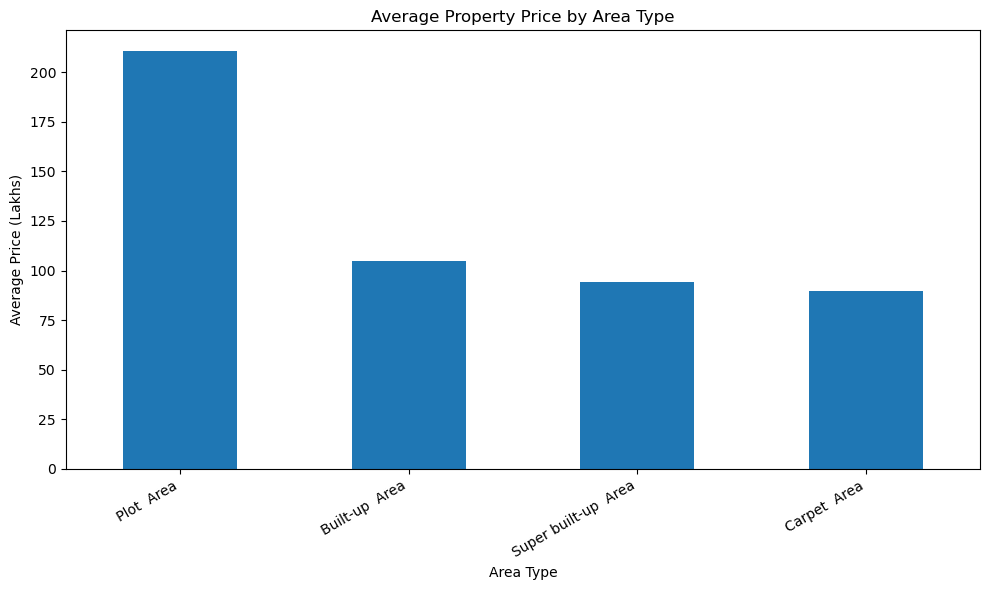

In [6]:
# Average property price by area type
avg_price_area = (
    df.groupby("area_type")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
avg_price_area.plot(kind="bar")
plt.title("Average Property Price by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

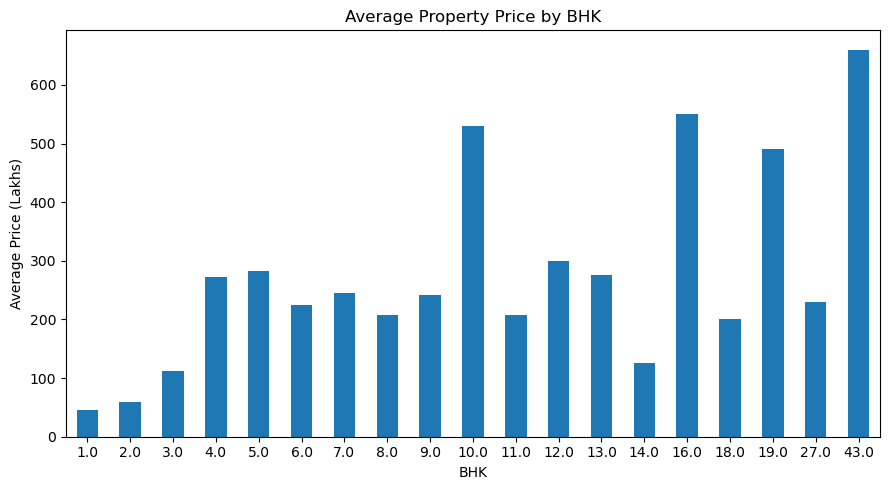

In [7]:
bhk_price = (
    df.groupby("bhk")["price"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(9, 5))
bhk_price.plot(kind="bar")
plt.title("Average Property Price by BHK")
plt.xlabel("BHK")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

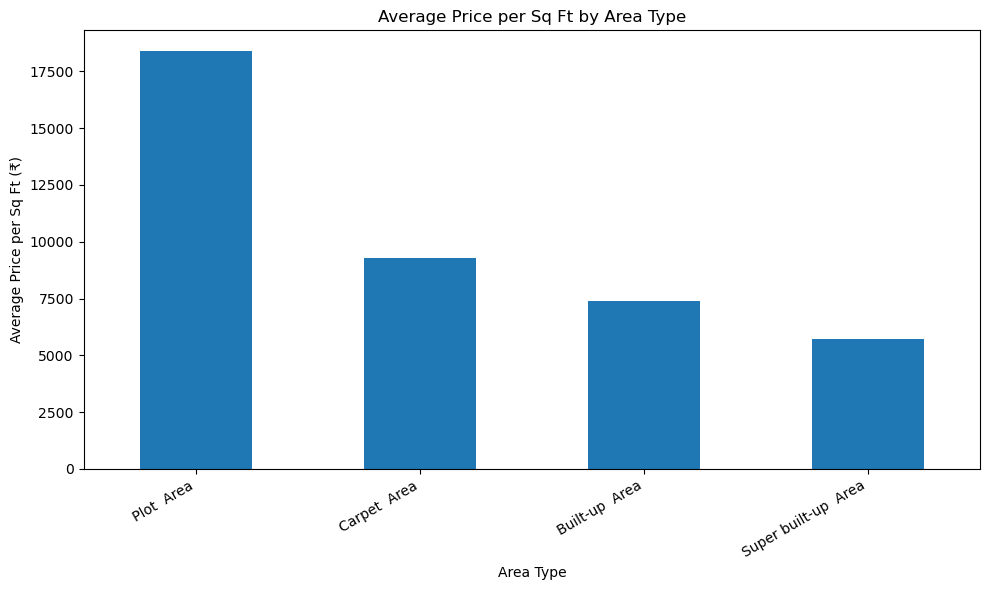

In [8]:
area_sqft = (
    df.groupby("area_type")["price_per_sqft"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
area_sqft.plot(kind="bar")
plt.title("Average Price per Sq Ft by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Average Price per Sq Ft (₹)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

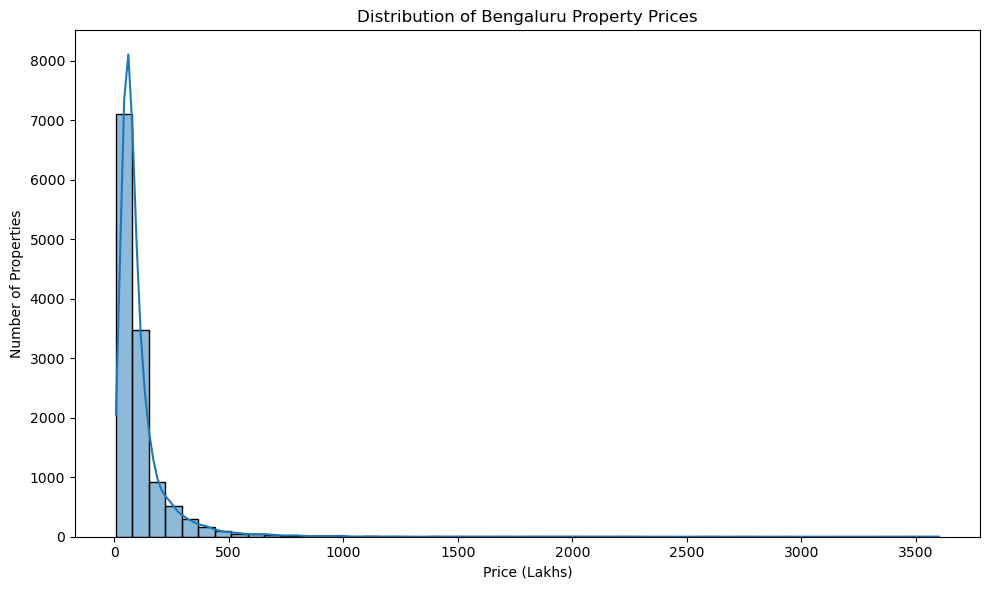

In [9]:
# Purpose: Understand how property prices are distributed across Bengaluru.
# Chart: Histogram with a density curve.
# X-axis: Property price in lakhs.
# Y-axis: Number of properties.
# Interpretation: Helps identify common price ranges and possible extreme values.

plt.figure(figsize=(10, 6))

# Create a histogram with 50 price intervals and a smooth density curve
sns.histplot(data=df, x="price", bins=50, kde=True)

# Add chart title and axis labels
plt.title("Distribution of Bengaluru Property Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Properties")

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

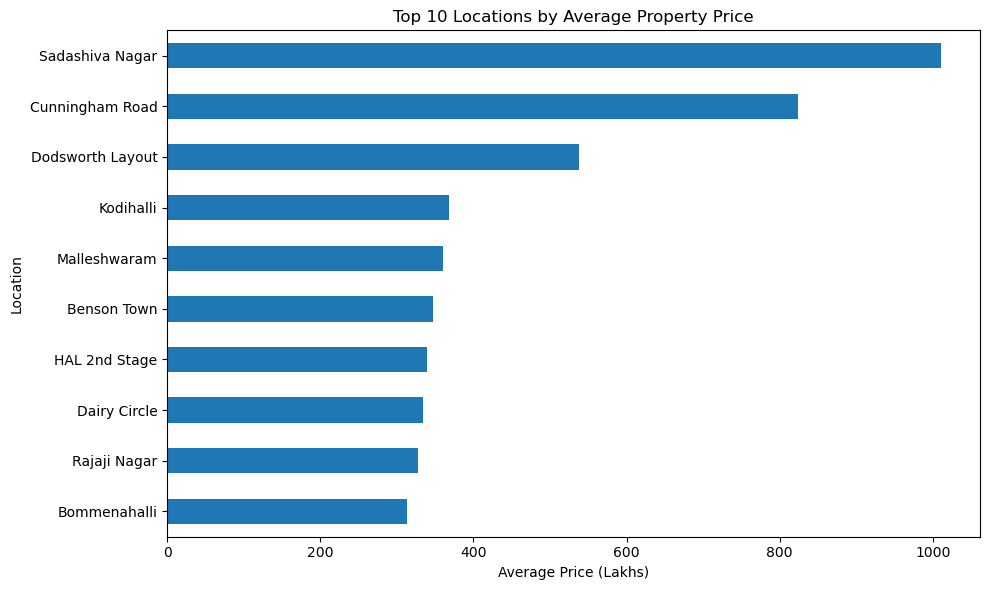

In [10]:
# Purpose: Identify the 10 locations with the highest average property prices.
# Chart: Horizontal bar chart.
# X-axis: Average property price in lakhs.
# Y-axis: Location.
# Note: Locations with very few properties can have misleading averages,
# so we include only locations with at least 10 records.

location_counts = df["location"].value_counts()

valid_locations = location_counts[location_counts >= 10].index

top_locations = (
    df[df["location"].isin(valid_locations)]
    .groupby("location")["price"]
    .mean()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_locations.plot(kind="barh")

plt.title("Top 10 Locations by Average Property Price")
plt.xlabel("Average Price (Lakhs)")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

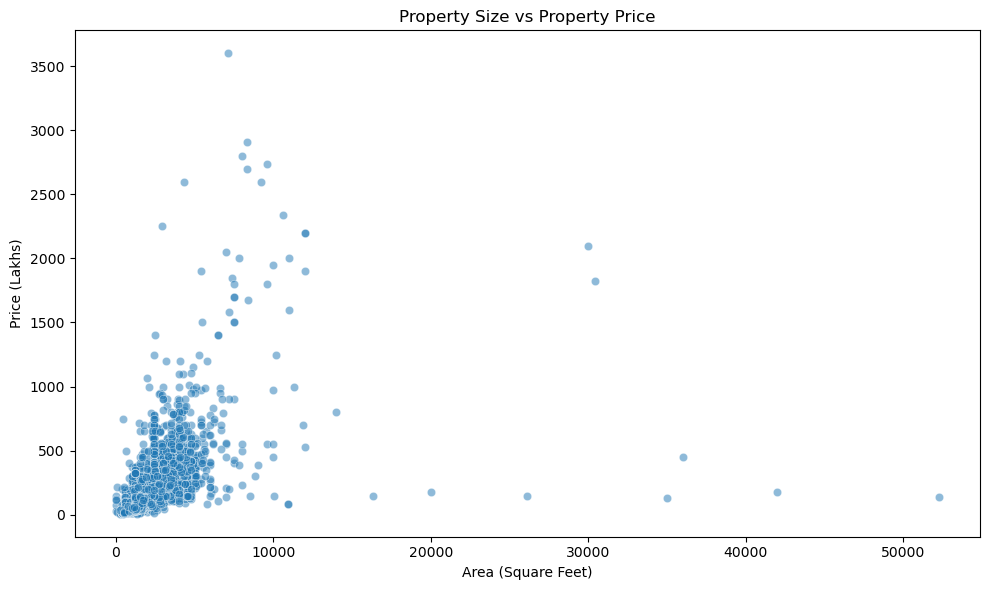

In [11]:
# Purpose: Explore the relationship between property size and total price.
# Chart: Scatter plot.
# X-axis: Property area in square feet.
# Y-axis: Property price in lakhs.
# Each point represents one property.
# Note: Unusual area values and extreme prices may affect the pattern.

# Keep only rows with valid positive area and price values
plot_df = df[
    (df["total_sqft_clean"] > 0) &
    (df["price"] > 0)
].copy()

plt.figure(figsize=(10, 6))

# Draw the scatter plot using the cleaned area column
sns.scatterplot(
    data=plot_df,
    x="total_sqft_clean",
    y="price",
    alpha=0.5
)

plt.title("Property Size vs Property Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("Price (Lakhs)")
plt.tight_layout()
plt.show()

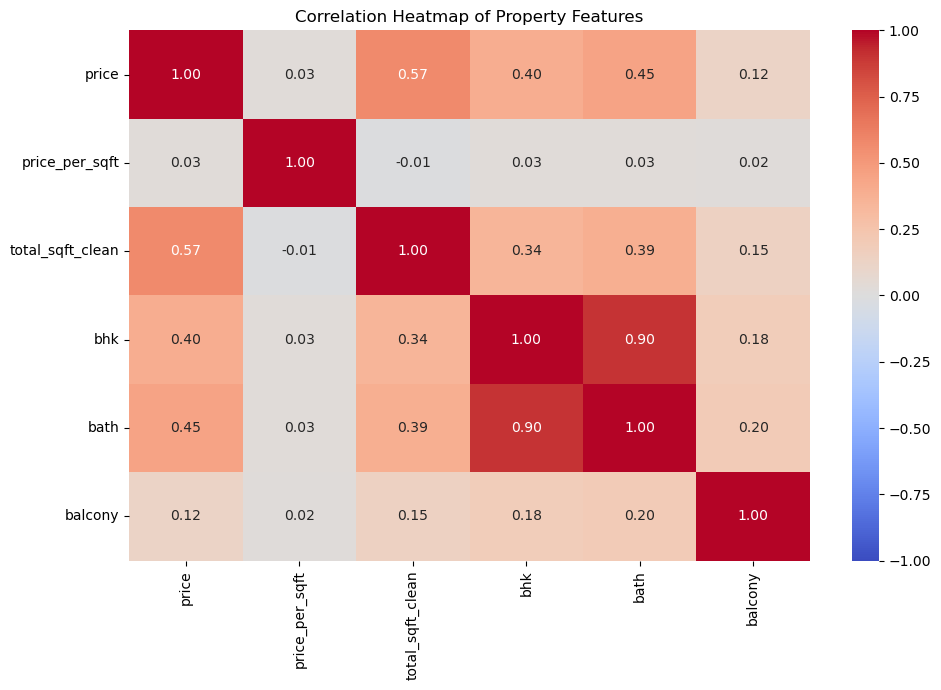

In [12]:
# Purpose: Measure relationships between numerical variables.
# Chart: Correlation heatmap.
# Values range from -1 to +1:
# +1 = strong positive relationship; -1 = strong negative relationship;
# 0 = little or no linear relationship.
# Note: Correlation does not prove causation.

# Select relevant numeric columns for correlation analysis
numeric_cols = [
    "price", "price_per_sqft", "total_sqft_clean",
    "bhk", "bath", "balcony"
]

corr = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))

# Display correlations using colors and numerical labels
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Property Features")
plt.tight_layout()
plt.show()

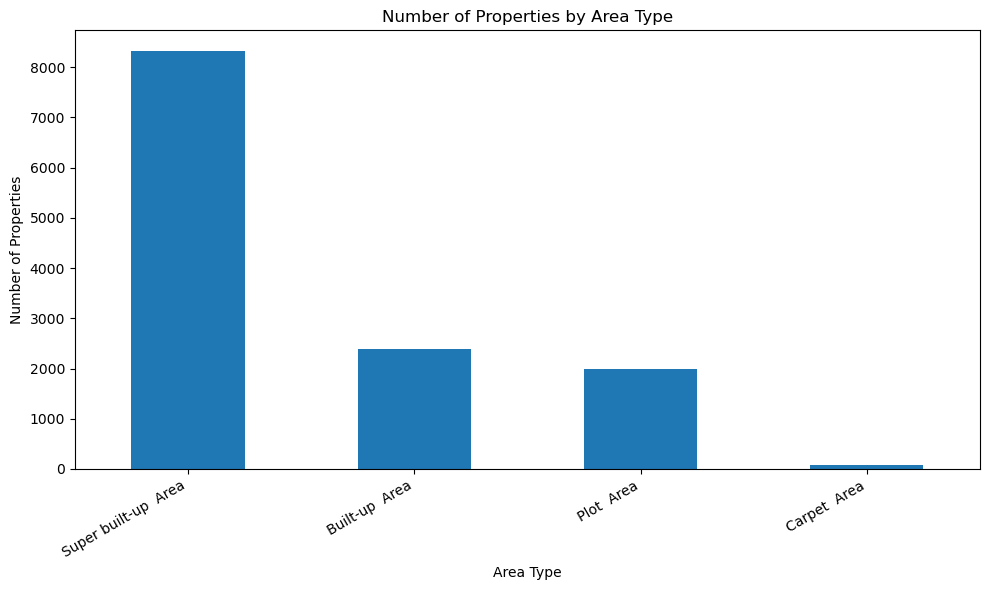

In [13]:
# Purpose: Compare how many properties belong to each area type.
# Chart: Bar chart.
# X-axis: Area type.
# Y-axis: Number of properties.
# Note: This shows the dataset's composition, not which area type is most expensive.

area_counts = df["area_type"].value_counts()

plt.figure(figsize=(10, 6))

# Display property counts for each area type
area_counts.plot(kind="bar")

plt.title("Number of Properties by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [14]:
# Purpose: Check for unusual values that may affect the analysis.
# We examine BHK, property size, total price, and price per square foot.
# Zero or negative values are flagged as invalid for these measures.
# Very large values are flagged for review, not automatically deleted.

check_cols = [
    "bhk",
    "total_sqft_clean",
    "price",
    "price_per_sqft"
]

print("Dataset rows:", len(df))

for col in check_cols:
    print(f"\n--- {col} ---")
    print("Missing values:", df[col].isna().sum())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Non-positive values:", (df[col] <= 0).sum())

# Show the 10 largest BHK values for manual review
display(
    df.nlargest(10, "bhk")[
        ["location", "size", "bhk", "total_sqft_clean", "price"]
    ]
)

Dataset rows: 12791

--- bhk ---
Missing values: 16
Minimum: 1.0
Maximum: 43.0
Non-positive values: 0

--- total_sqft_clean ---
Missing values: 46
Minimum: 1.0
Maximum: 52272.0
Non-positive values: 0

--- price ---
Missing values: 0
Minimum: 8.0
Maximum: 3600.0
Non-positive values: 0

--- price_per_sqft ---
Missing values: 46
Minimum: 267.8298133
Maximum: 12000000.0
Non-positive values: 0


,location,size,bhk,total_sqft_clean,price
4618,Munnekollal,43 Bedroom,43.0,2400.0,660.0
1710,2Electronic City Phase II,27 BHK,27.0,8000.0,230.0
3340,1Hanuman Nagar,19 BHK,19.0,2000.0,490.0
11154,1Kasavanhalli,18 Bedroom,18.0,1200.0,200.0
3570,Koramangala Industrial Layout,16 BHK,16.0,10000.0,550.0
4842,1Channasandra,14 BHK,14.0,1250.0,125.0
9624,1Hoysalanagar,13 BHK,13.0,5425.0,275.0
6391,Mysore Road,12 Bedroom,12.0,2232.0,300.0
459,1 Giri Nagar,11 BHK,11.0,5000.0,360.0
1759,1 Ramamurthy Nagar,11 Bedroom,11.0,1200.0,170.0


In [15]:
# Purpose: Segment properties by bedroom count and area type.
# This table compares average price and average price per square foot.
# Groups with few records should be interpreted cautiously.

segment_summary = (
    df.groupby(["area_type", "bhk"], dropna=False)
    .agg(
        property_count=("price", "count"),
        avg_price_lakhs=("price", "mean"),
        avg_price_per_sqft=("price_per_sqft", "mean")
    )
    .round(2)
    .reset_index()
)

display(segment_summary.head(20))

,area_type,bhk,property_count,avg_price_lakhs,avg_price_per_sqft
0,Built-up Area,1.0,152,56.27,7986.42
1,Built-up Area,2.0,999,57.15,5184.22
2,Built-up Area,3.0,777,106.80,6054.55
3,Built-up Area,4.0,302,237.64,8281.80
4,Built-up Area,5.0,71,207.91,16577.24
5,Built-up Area,6.0,47,160.70,6842.60
6,Built-up Area,7.0,26,185.50,95454.28
7,Built-up Area,8.0,16,138.88,7557.76
8,Built-up Area,9.0,7,192.86,4357.83
9,Built-up Area,10.0,1,200.00,2777.78


In [16]:
# Purpose: Summarize key metrics for the final report and dashboard.
# All results are calculated from the currently loaded dataset.
# Price is assumed to be in lakhs, as used in the source dataset.

summary = {
    "Total property records": len(df),
    "Unique locations": df["location"].nunique(),
    "Average price (lakhs)": round(df["price"].mean(), 2),
    "Median price (lakhs)": round(df["price"].median(), 2),
    "Average price per sqft": round(df["price_per_sqft"].mean(), 2),
    "Average property size (sqft)": round(df["total_sqft_clean"].mean(), 2),
    "Missing locations": df["location"].isna().sum(),
    "Missing prices": df["price"].isna().sum(),
    "Missing property sizes": df["total_sqft_clean"].isna().sum()
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Total property records,12791.00
1,Unique locations,1294.00
2,Average price (lakhs),114.32
3,Median price (lakhs),73.00
4,Average price per sqft,8022.90
5,Average property size (sqft),1569.60
6,Missing locations,1.00
7,Missing prices,0.00
8,Missing property sizes,46.00
